# Part D: Clinical review figure

This notebook audits the raw file before plotting, applies explicit data-quality rules, and produces one finished 2×2 clinical review figure at 300 dpi.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA = Path.cwd()
if not (DATA / 'vitals_10k.csv').exists():
    DATA = DATA / 'Week 03'
sys.path.insert(0, str(DATA))
import vizlib

OUTPUT = DATA / 'figures'
OUTPUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300})
print(f'Data directory: {DATA.resolve()}')
print('Rows removed: none before the required raw-data inspection.')

Data directory: D:\University\ML Lab\Week 03
Rows removed: none before the required raw-data inspection.


## Required raw-data inspection

The following four commands are intentionally run before any cleaning or plotting.

In [2]:
raw = pd.read_csv(DATA / 'vitals_10k.csv')
raw.info()
display(raw.describe().T)
display(raw.ward.value_counts(dropna=False))
print(raw.admit_date.head(20).tolist())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  str    
 1   admit_date      10000 non-null  str    
 2   ward            10000 non-null  str    
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  str    
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), str(4)
memory usage: 1.2 MB


,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.113800,16.639728,18.0,47.000000,58.0000,69.0000,97.00
systolic,10000.0,137.656700,22.597192,92.0,119.000000,128.0000,160.0000,199.00
diastolic,10000.0,79.628200,13.134109,45.0,69.000000,78.0000,90.0000,125.00
map_mmhg,10000.0,98.970690,15.830095,65.3,85.700000,94.3000,113.7000,149.70
heart_rate,10000.0,78.833100,20.557021,0.0,69.000000,78.0000,87.0000,415.00
spo2,10000.0,96.724000,2.239671,81.0,96.000000,97.0000,98.0000,100.00
bmi,10000.0,66.177040,190.996849,0.0,24.000000,27.6000,31.2000,999.00
chol_mmol_l,10000.0,4.823818,1.010410,2.1,4.140000,4.8200,5.5100,8.79
glucose_mmol_l,10000.0,6.550060,1.145823,5.1,5.700000,6.3000,7.1000,13.90
los_days,10000.0,2.309091,8.923347,0.0,0.610000,1.3800,2.5700,273.65


ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

['2026-01-19', '08-Mar-2026', '2026-02-26', '27/02/2026', '09/01/2026', '01-Apr-2026', '17-Apr-2026', '24-Mar-2026', '14-Apr-2026', '02-Jan-2026', '10/03/2026', '10/02/2026', '12-Apr-2026', '29/03/2026', '17-Apr-2026', '12/02/2026', '2026-03-28', '2026-02-03', '11-Apr-2026', '08/01/2026']


### Problems found and rules applied

1. **Ward labels:** 12 spellings represent four wards. Strip whitespace, remove periods, lowercase, and map every spelling to one canonical ward name.
2. **Admission dates:** dates use ISO, slash, and month-name formats. Parse with `format='mixed'`, `dayfirst=True`, and `errors='coerce'`; no dates became missing.
3. **Heart rate:** values below 30 or above 250 bpm are implausible for this review. Remove those 37 rows (8 zero readings and 29 readings above 250) rather than allowing device faults to distort plots.
4. **BMI:** values below 12 or above 60 kg/m² are impossible for this review and include the explicit 0 and 999 codes. Remove those 486 rows.

The 18 long stays above 30 days are retained: a long admission is possible, so it is not silently treated as an error without a stated clinical rule. The separate wide ward LOS file is reshaped with `melt()` for Panel 2; that reshape removes no observations.

In [3]:
ward_map = {
    'general medicine': 'General Medicine',
    'gen medicine': 'General Medicine',
    'cardiology': 'Cardiology',
    'cardio': 'Cardiology',
    'day surgery': 'Day Surgery',
    'day-surgery': 'Day Surgery',
    'intensive care': 'ICU',
    'icu': 'ICU',
}
clean = raw.copy()
clean['ward'] = (clean['ward'].str.strip().str.lower().str.replace('.', '', regex=False).map(ward_map))
clean['admit_date'] = pd.to_datetime(clean['admit_date'], format='mixed', dayfirst=True, errors='coerce')
invalid_heart_rate = (clean['heart_rate'] < 30) | (clean['heart_rate'] > 250)
invalid_bmi = (clean['bmi'] < 12) | (clean['bmi'] > 60)
invalid_date_or_ward = clean['admit_date'].isna() | clean['ward'].isna()
print('Rows with unmapped ward or unparsed date:', int(invalid_date_or_ward.sum()))
print('Rows removed for implausible heart rate:', int(invalid_heart_rate.sum()))
print('Rows removed for impossible BMI:', int(invalid_bmi.sum()))
analysis = clean.loc[~invalid_heart_rate & ~invalid_bmi & ~invalid_date_or_ward].copy()
print('Rows retained for analysis:', len(analysis), 'of', len(raw))
print('Canonical ward counts:\n', analysis['ward'].value_counts())

Rows with unmapped ward or unparsed date: 0
Rows removed for implausible heart rate: 37
Rows removed for impossible BMI: 486
Rows retained for analysis: 9478 of 10000
Canonical ward counts:
 ward
General Medicine    3814
Cardiology          2539
ICU                 1729
Day Surgery         1396
Name: count, dtype: int64


## Choosing the four panels

- **Panel 1:** the length-of-stay distribution asks whether stays are concentrated or strongly right-skewed. It uses an explicit 0.5-day bin width.
- **Panel 2:** the length-of-stay box plot asks whether typical stay length differs across canonical wards.
- **Panel 3:** the diastolic–MAP scatter asks whether the strongest non-duplicate blood-pressure relationship is approximately linear.
- **Panel 4:** the heatmap asks which numeric measures are correlated enough to merit the scatter. It is pinned to `vmin=-1`, `vmax=1`, uses a diverging map, and masks the upper triangle.

In [4]:
numeric_columns = ['age', 'systolic', 'diastolic', 'map_mmhg', 'heart_rate', 'spo2', 'bmi', 'chol_mmol_l', 'glucose_mmol_l', 'los_days', 'readmitted_30d', 'risk_score']
correlations = analysis[numeric_columns].corr()
pair_candidates = correlations.where(~np.eye(len(correlations), dtype=bool)).stack().sort_values(ascending=False)
print('Strongest non-self numeric pair:', pair_candidates.index[0], '=', pair_candidates.iloc[0].round(3))
print('Selected scatter pair: diastolic and MAP; r =', correlations.loc['diastolic', 'map_mmhg'].round(3))
print('Rows removed before correlation: heart-rate rule + BMI rule + date/ward parse rule.')

Strongest non-self numeric pair: ('diastolic', 'map_mmhg') = 0.976
Selected scatter pair: diastolic and MAP; r = 0.976
Rows removed before correlation: heart-rate rule + BMI rule + date/ward parse rule.


Wide LOS rows reshaped: 4018 rows to 10000 long observations; rows removed: 0 (melt is a reshape, not a filter).


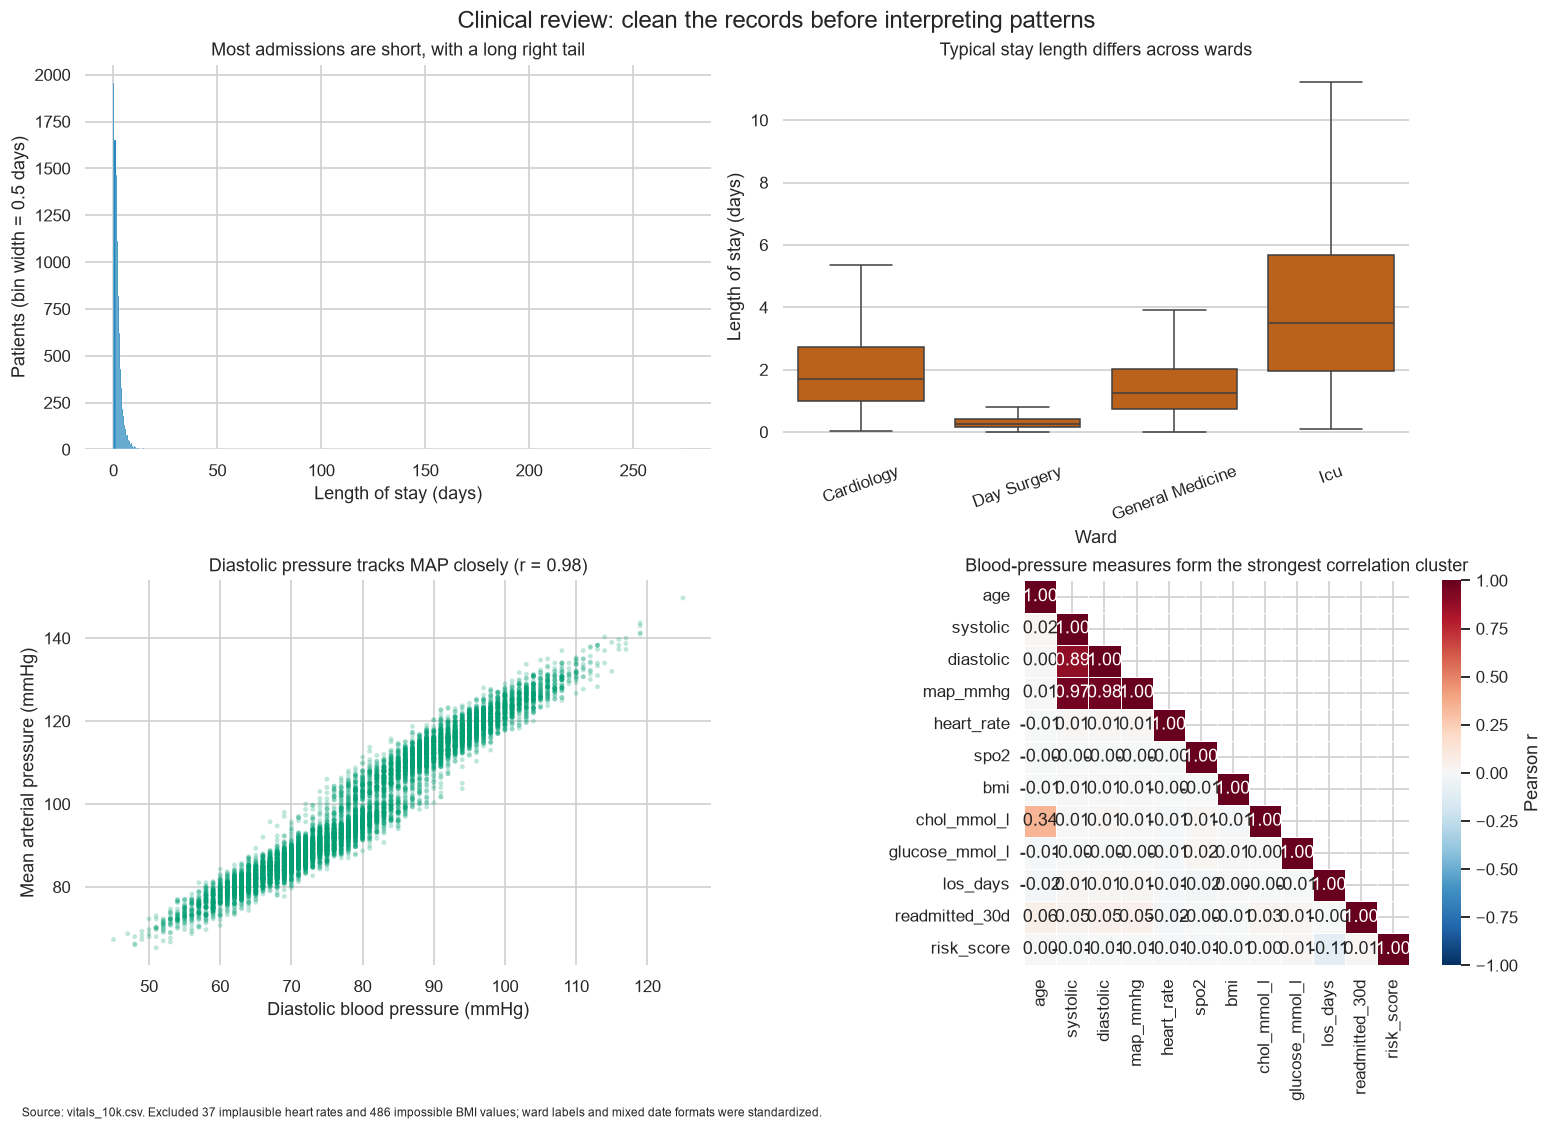

Saved: d:\University\ML Lab\Week 03\figures\04_clinical_review_figure.png


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
series = vizlib.PALETTE['series']

# Panel 1: distribution.
bin_width = 0.5
los_bins = np.arange(0, analysis['los_days'].max() + bin_width, bin_width)
ax[0, 0].hist(analysis['los_days'], bins=los_bins, color=series[0], edgecolor='white', linewidth=0.2)
ax[0, 0].set_title('Most admissions are short, with a long right tail')
ax[0, 0].set_xlabel('Length of stay (days)')
ax[0, 0].set_ylabel(f'Patients (bin width = {bin_width} days)')

# Panel 2: reshape the supplied wide LOS file before using Seaborn.
ward_los_wide = pd.read_csv(DATA / 'ward_los_wide.csv')
los_long = ward_los_wide.melt(var_name='ward', value_name='los_days').dropna(subset=['los_days'])
print('Wide LOS rows reshaped:', len(ward_los_wide), 'rows to', len(los_long), 'long observations; rows removed: 0 (melt is a reshape, not a filter).')
sns.boxplot(data=los_long, x='ward', y='los_days', order=['Cardiology', 'Day Surgery', 'General Medicine', 'Icu'], color=series[1], showfliers=False, ax=ax[0, 1])
ax[0, 1].set_title('Typical stay length differs across wards')
ax[0, 1].set_xlabel('Ward')
ax[0, 1].set_ylabel('Length of stay (days)')
ax[0, 1].tick_params(axis='x', rotation=20)

# Panel 3: strongest non-duplicate blood-pressure relationship.
ax[1, 0].scatter(analysis['diastolic'], analysis['map_mmhg'], s=10, alpha=0.25, color=series[2], edgecolors='none')
ax[1, 0].set_title(f'Diastolic pressure tracks MAP closely (r = {correlations.loc["diastolic", "map_mmhg"]:.2f})')
ax[1, 0].set_xlabel('Diastolic blood pressure (mmHg)')
ax[1, 0].set_ylabel('Mean arterial pressure (mmHg)')
# Panel 4: signed correlation heatmap.
heatmap_columns = ['age', 'systolic', 'diastolic', 'map_mmhg', 'heart_rate', 'spo2', 'bmi', 'chol_mmol_l', 'glucose_mmol_l', 'los_days', 'readmitted_30d', 'risk_score']
heatmap_corr = analysis[heatmap_columns].corr()
mask = np.triu(np.ones_like(heatmap_corr, dtype=bool), k=1)
sns.heatmap(heatmap_corr, mask=mask, cmap=vizlib.PALETTE.get('diverging', 'RdBu_r'), vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', square=True, linewidths=0.4, cbar_kws={'label': 'Pearson r'}, ax=ax[1, 1])
ax[1, 1].set_title('Blood-pressure measures form the strongest correlation cluster')
ax[1, 1].set_xlabel('')
ax[1, 1].set_ylabel('')
for axis in ax.flat:
    axis.spines[['top', 'right', 'left', 'bottom']].set_visible(False)

fig.suptitle('Clinical review: clean the records before interpreting patterns', fontsize=16)
fig.text(0.01, -0.01, 'Source: vitals_10k.csv. Excluded 37 implausible heart rates and 486 impossible BMI values; ward labels and mixed date formats were standardized.', fontsize=8)
fig.savefig(OUTPUT / '04_clinical_review_figure.png', dpi=300, bbox_inches='tight')
plt.show()

print('Saved:', OUTPUT / '04_clinical_review_figure.png')